In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report,ConfusionMatrixDisplay)

In [2]:
# Load the loan approval dataset
df = pd.read_csv("loan_approval_dataset.csv")
# Display first five rows
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,NotGraduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,NotGraduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [3]:
# Check dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4269 non-null   int64
 1   no_of_dependents          4269 non-null   int64
 2   education                 4269 non-null   str  
 3   self_employed             4269 non-null   str  
 4   income_annum              4269 non-null   int64
 5   loan_amount               4269 non-null   int64
 6   loan_term                 4269 non-null   int64
 7   cibil_score               4269 non-null   int64
 8   residential_assets_value  4269 non-null   int64
 9   commercial_assets_value   4269 non-null   int64
 10  luxury_assets_value       4269 non-null   int64
 11  bank_asset_value          4269 non-null   int64
 12  loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB


In [4]:
# Check dataset dimensions
print(df.shape)

(4269, 13)


In [5]:
# Check for missing values
print(df.isnull().sum())

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64


In [6]:
# Check loan status categories
print(df['loan_status'].unique())

<StringArray>
['Approved', 'Rejected']
Length: 2, dtype: str


In [7]:
# Select independent variables (X)

X = df[[
    'no_of_dependents',
    'education',
    'self_employed',
    'income_annum',
    'loan_amount',
    'loan_term',
    'cibil_score',
    'residential_assets_value',
    'commercial_assets_value',
    'luxury_assets_value',
    'bank_asset_value'
]]

# Select dependent variable (Y)

y = df['loan_status']

print("Independent Variables:")
display(X.head())

print("\nDependent Variable:")
display(y.head())

Independent Variables:


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000
1,0,NotGraduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000
4,5,NotGraduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000



Dependent Variable:


0    Approved
1    Rejected
2    Rejected
3    Rejected
4    Rejected
Name: loan_status, dtype: str

In [8]:
# Convert categorical variables into dummy variables
X = pd.get_dummies(
    X,
    columns=['education', 'self_employed'],
    drop_first=True,
    dtype=int
)
# Display updated independent variables
X.head()

,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,education_NotGraduate,self_employed_Yes
0,2,9600000,29900000,12,778,2400000,17600000,22700000,8000000,0,0
1,0,4100000,12200000,8,417,2700000,2200000,8800000,3300000,1,1
2,3,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0,0
3,3,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0,0
4,5,9800000,24200000,20,382,12400000,8200000,29400000,5000000,1,1


In [10]:
# Remove extra spaces from loan status
df['loan_status'] = df['loan_status'].str.strip()
# Convert loan status into numerical values
y = df['loan_status'].map({
    'Approved': 1,
    'Rejected': 0
})
# Check encoded values
print(y.head())
print("\nUnique encoded values:", y.unique())
print("\nMissing values:", y.isnull().sum())

0    1
1    0
2    0
3    0
4    0
Name: loan_status, dtype: int64

Unique encoded values: [1 0]

Missing values: 0


In [12]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)
# Display dataset shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (3415, 11)
X_test shape: (854, 11)
y_train shape: (3415,)
y_test shape: (854,)


In [16]:
# STEP 1: Select independent variables

X = df[[
    'no_of_dependents',
    'education',
    'self_employed',
    'income_annum',
    'loan_amount',
    'loan_term',
    'cibil_score',
    'residential_assets_value',
    'commercial_assets_value',
    'luxury_assets_value',
    'bank_asset_value'
]]

# STEP 2: Dummy variable encoding

X = pd.get_dummies(
    X,
    columns=['education', 'self_employed'],
    drop_first=True,
    dtype=int
)

# STEP 3: Encode target variable

y = df['loan_status'].str.strip().map({
    'Approved': 1,
    'Rejected': 0
})

# STEP 4: Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# STEP 5: Train Logistic Regression model

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# STEP 6: Generate predictions

y_pred = model.predict(X_test)

print("Model trained and predictions generated successfully!")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Text columns in X_test:",
      X_test.select_dtypes(include='object').columns.tolist())

Model trained and predictions generated successfully!
Training shape: (3415, 11)
Testing shape: (854, 11)
Text columns in X_test: []


In [17]:
# Predict loan status
y_pred = model.predict(X_test)

In [18]:
# Create Logistic Regression model
model = LogisticRegression(max_iter=1000)
# Train the model
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [22]:
# Compare actual and predicted loan status

comparison = pd.DataFrame({
    'Actual Loan Status': y_test.map({
        1: 'Approved',
        0: 'Rejected'
    }).values,

    'Predicted Loan Status': pd.Series(y_pred).map({
        1: 'Approved',
        0: 'Rejected'
    }).values
})

comparison.head(10)

,Actual Loan Status,Predicted Loan Status
0,Rejected,Rejected
1,Approved,Approved
2,Rejected,Rejected
3,Approved,Approved
4,Approved,Approved
5,Approved,Approved
6,Approved,Approved
7,Rejected,Rejected
8,Approved,Approved
9,Rejected,Rejected


In [23]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [26]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Generate classification report
report = classification_report(
    y_test,
    y_pred,
    target_names=['Rejected', 'Approved']
)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")
print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n", report)

Accuracy: 0.7985948477751756
Accuracy Percentage: 79.86 %

Confusion Matrix:
 [[194 124]
 [ 48 488]]

Classification Report:
               precision    recall  f1-score   support

    Rejected       0.80      0.61      0.69       318
    Approved       0.80      0.91      0.85       536

    accuracy                           0.80       854
   macro avg       0.80      0.76      0.77       854
weighted avg       0.80      0.80      0.79       854



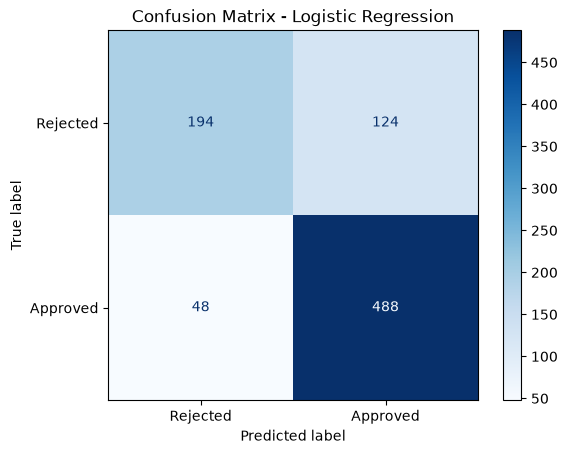

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Rejected', 'Approved']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

### Conclusion

In this project, Logistic Regression was used to predict loan approval status based on applicant details and financial information.

The model achieved an accuracy of approximately **79.86%** on the test dataset. It performed better in identifying approved loan applications, with a recall of 91%, compared to 61% for rejected applications.

The confusion matrix shows that the model correctly classified 194 rejected and 488 approved applications. However, 124 rejected applications were incorrectly predicted as approved.

Overall, this project demonstrates how Logistic Regression can be applied to loan classification and financial decision-making. Further improvements could help the model identify rejected applications more accurately.